# Setup and data

**Goal.** Confirm the libraries import, and take a first look at price history and headline sentiment.

**Method.** Print the TensorFlow, PyTorch, and Transformers versions. Download NQ and NVDA with `yfinance`. Score headlines with FinBERT (`ProsusAI/finbert`).

**Result.** The stack imports (TensorFlow 2.21, PyTorch 2.15, Transformers 5.24 on the machine used for this log). The sentiment cells are a setup check. They are not used in the trading tests. Massive keys are read from `.env` later and are not in this notebook.


In [2]:
import tensorflow as tf, torch, transformers, yfinance as yf
print("TF", tf.__version__, "| torch", torch.__version__, "| transformers", transformers.__version__)
df = yf.download("NQ=F", period="1y", multi_level_index=False)
df.tail()


TF 2.21.0 | torch 2.15.0 | transformers 5.24.1


[*********************100%***********************]  1 of 1 completed


,Close,High,Low,Open,Volume
Date,,,,,
2026-11-19,26600.25,27838.00,26436.00,27174.0,1002226
2026-11-20,25126.50,26603.50,24976.50,26600.0,1395899
2026-11-23,26808.00,27137.00,25426.75,25561.5,1079635
2026-11-24,26275.75,27036.00,25998.00,26888.0,1079635
2026-11-25,26103.25,26350.75,25027.50,26279.5,909521


[*********************100%***********************]  1 of 1 completed


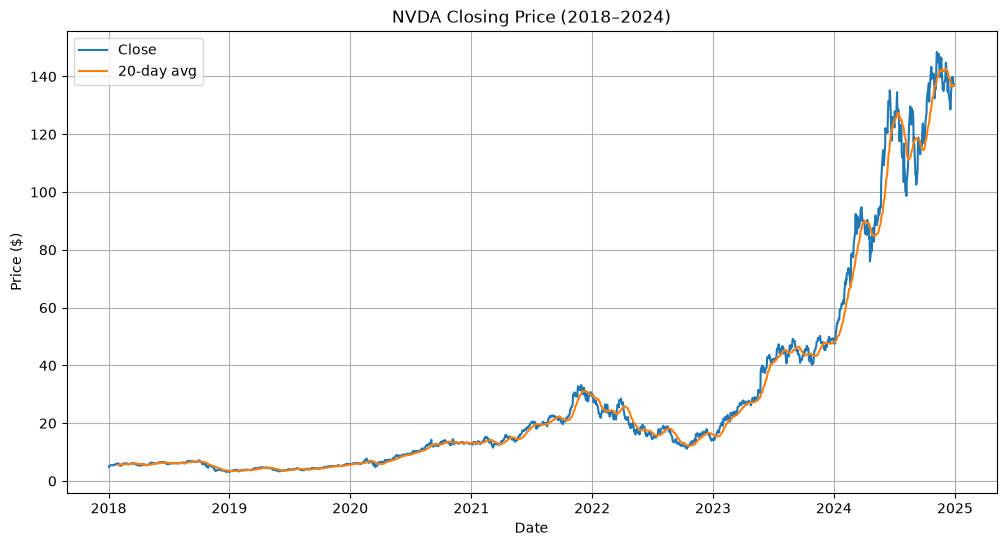

In [5]:
import yfinance as yf
import matplotlib.pyplot as plt

# Fetch historical data
df = yf.download("NVDA", start="2018-01-01", end="2024-12-31", multi_level_index=False)

# Plot the line chart
plt.figure(figsize=(12, 6))
plt.plot(df.index, df["Close"], label="Close")
plt.plot(df.index, df["Close"].rolling(20).mean(), label="20-day avg")
plt.title("NVDA Closing Price (2018–2024)")
plt.xlabel("Date")
plt.ylabel("Price ($)")
plt.legend()
plt.grid(True)
plt.show()


In [7]:
from transformers import pipeline

# Load sentiment analysis pipeline
classifier = pipeline("text-classification", model="ProsusAI/finbert")

# Example financial headlines
headlines = [
    "NVIDIA beats earnings estimates as data center sales surge",
    "Tesla shares fall after weak delivery numbers",
    "Fed holds rates steady, signals possible cuts next year",
    "Apple to hold annual shareholder meeting in March",
    "Oil prices drop on rising supply concerns",
]

# Analyze sentiments
results = classifier(headlines)

# Display results
for h, r in zip(headlines, results):
    print(f"{r['label'].upper():8} ({r['score']:.0%})  {h}")


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

POSITIVE (89%)  NVIDIA beats earnings estimates as data center sales surge
NEGATIVE (97%)  Tesla shares fall after weak delivery numbers
NEUTRAL  (51%)  Fed holds rates steady, signals possible cuts next year
NEUTRAL  (94%)  Apple to hold annual shareholder meeting in March
NEGATIVE (96%)  Oil prices drop on rising supply concerns


In [8]:
import yfinance as yf
from transformers import pipeline

# Load sentiment analysis pipeline
classifier = pipeline("text-classification", model="ProsusAI/finbert")

tickers = ["CBRS", "MRVL", "XLE"]

for t in tickers:
    # Fetch recent news headlines
    news = yf.Ticker(t).news
    headlines = []
    for item in news:
        title = item.get("content", {}).get("title") or item.get("title")
        if title:
            headlines.append(title)

    print(f"\n===== {t} ({len(headlines)} headlines) =====")
    if not headlines:
        print("No headlines found")
        continue

    # Analyze sentiments
    results = classifier(headlines)

    # Display results + overall score
    score = 0
    for h, r in zip(headlines, results):
        print(f"{r['label'].upper():8} ({r['score']:.0%})  {h}")
        if r["label"] == "positive":
            score += 1
        elif r["label"] == "negative":
            score -= 1
    print(f"Net sentiment: {score:+d}")


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]


===== CBRS (10 headlines) =====
NEGATIVE (75%)  5 Beaten-Down Stocks Insiders Are Still Dumping (Even After a 50% Crash)
NEGATIVE (87%)  CEO of $21 billion Cerebras says it’s minted 1,000 employees into millionaires—but warns that drastic changes in fortunes can be ‘really stressful’
NEUTRAL  (89%)  Follow the Smart Money: This Billionaire Tech Investor Has Been Loading Up On Shares of These 3 AI Chip Stocks
NEUTRAL  (88%)  Cathie Wood Just Bought $21 Million of Cerebras Across 2 ARK Funds
NEUTRAL  (79%)  Why Did Cerebras Stock Soar Today?
NEUTRAL  (91%)  3 Growth Stocks To Watch In November 2026
NEUTRAL  (35%)  At AI Summit, Industry Titans Wave Off Market Woes—and Defend Jensen Huang
NEUTRAL  (75%)  Cerebras Stock Looks Like a Buy as Customer Base Expands
NEUTRAL  (92%)  The Short Seller Who Called Out Nvidia Has a New Target
NEUTRAL  (84%)  Cerebras Is Targeting a 3x Revenue Jump in 2027. Is the Stock a Buy?
Net sentiment: -2

===== MRVL (10 headlines) =====
NEUTRAL  (71%)  Why Did